# 11 — End-to-end GCOV capstone: detecting a summer clear-cut

**Goal:** chain everything — product, AOI, QC, dB, statistics, export — on a real question:
*is the July–August 2026 clear-cut of the Vosges site visible in the NISAR GCOV time series?*

The single-date product of notebooks 01–10 is complemented here by the 11 GCOV dates (track 144
ascending, June–November 2026) that the feasibility study already cut to the site (GeoTIFF, HH and
HV γ⁰ at 20 m; `scripts/04_fetch_nisar.py`). If they are absent, only the single date is used.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "11"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency", "aoi_bounds"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])
from nisar_s1.polarimetry import to_db
from nisar_s1.grid import polygon_mask, read_geotiff, to_grid
from nisar_s1.optical import Raster, save_raster
from nisar_s1.config import load_params
import geopandas as gpd, re

## Step 1–5 in one cell: open → profile → AOI → QC → dB, per land unit

In [2]:
def gcov_units(h5, frequency, bounds, sites, erode=True):
    prof = P.product_profile(h5)
    grid = prof.grids[frequency]
    win = P.window_from_bounds(grid, bounds)
    m = P.read_layer(h5, grid, "mask", win, nodata_zero=False)
    valid = (m != 0) & (m != 255)
    ref = Raster(np.zeros(win.shape, "float32"), win.transform, win.crs)
    out = {}
    for _, s in sites.to_crs(grid.epsg).iterrows():
        mk = polygon_mask([s.geometry], ref, erode_m=abs(grid.dx) if erode else 0) & valid
        for t in grid.terms:
            out[(s.role, t)] = float(to_db(np.nanmedian(P.read_layer(h5, grid, t, win)[mk])))
    return prof, out

sites = gpd.read_file(kit["aoi"]["site_polygons"])
with src_ctx() as h5:
    prof, single = gcov_units(h5, session["frequency"], session["aoi_bounds"], sites)
pd.Series(single).unstack().round(2)

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5


,HHHH,HVHV
control,-4.72,-9.20
cut,-8.26,-13.58


## Time series from the feasibility-study GeoTIFFs

In [3]:
gdir = Path(load_params()["chemins"]["processed"]) / "nisar" / "A144F26" / "GCOV"
files = sorted(gdir.glob("*__HVHV.tif")) if gdir.exists() else []
print(len(files), "HV dates found in", gdir)
rows = []
for i, f in enumerate(files, 1):
    date = re.search(r"_(\d{8})T", f.name).group(1)
    for pol in ("HHHH", "HVHV"):
        r = read_geotiff(f.with_name(f.name.replace("__HVHV", f"__{pol}")))
        for _, s in sites.to_crs(r.crs).iterrows():
            mk = polygon_mask([s.geometry], r, erode_m=20)
            rows.append({"date": pd.Timestamp(date), "unit": s.role, "pol": pol[:2],
                         "dB": float(to_db(np.nanmedian(np.where(r.data > 0, r.data, np.nan)[mk])))})
    print(f"[{i}/{len(files)}] {date}", end="  ")
ts = pd.DataFrame(rows)

11 HV dates found in /media/dell/Transcend1/nisar_data/processed/nisar/A144F26/GCOV


[1/11] 20260624  [2/11] 20260706  [3/11] 20260718  [4/11] 20260811  [5/11] 20260823  [6/11] 20260904  

[7/11] 20260916  [8/11] 20260928  [9/11] 20261010  [10/11] 20261022  

[11/11] 20261103  

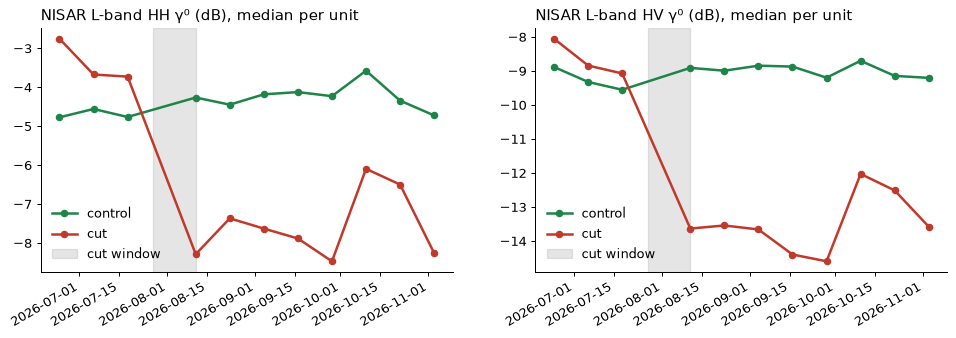

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax, pol in zip(axs, ["HH", "HV"]):
    for unit, c in [("control", "#1e8449"), ("cut", "#c0392b")]:
        d = ts[(ts.pol == pol) & (ts.unit == unit)].sort_values("date")
        ax.plot(d.date, d.dB, "-o", color=c, label=unit, lw=2, ms=5)
    ax.axvspan(pd.Timestamp("2026-07-27"), pd.Timestamp("2026-08-11"), color="#999999", alpha=0.25, label="cut window")
    ax.set_title(f"NISAR L-band {pol} γ⁰ (dB), median per unit", loc="left"); ax.legend(frameon=False)
fig.autofmt_xdate(); fig.savefig(OUT / "11_timeseries.png", dpi=120, bbox_inches="tight"); plt.show()

In [5]:
piv = ts.pivot_table(index=["pol", "date"], columns="unit", values="dB")
piv["cut - control"] = piv["cut"] - piv["control"]
before = piv[piv.index.get_level_values("date") < "2026-07-27"].groupby("pol")["cut - control"].mean()
after = piv[piv.index.get_level_values("date") > "2026-08-11"].groupby("pol")["cut - control"].mean()
summary = pd.DataFrame({"contrast before (dB)": before, "contrast after (dB)": after})
summary["change (dB)"] = summary.iloc[:, 1] - summary.iloc[:, 0]
summary.round(2)

,contrast before (dB),contrast after (dB),change (dB)
pol,,,
HH,1.31,-3.23,-4.54
HV,0.60,-4.48,-5.08


**Interpretation.** Before the cut, cut and control behave alike. After it, HV of the cut drops by
several dB relative to the control and stays low: L-band cross-pol sees the loss of the tree volume.
This is the result of the feasibility study (NISAR HV change, AUC ≈ 0.9 on this site) reproduced
from the raw products in a few cells.

In [6]:
checks = {
    "single-date contrast computed": len(single) == 4,
    "time series found": len(files) >= 5,
    "HV contrast drops after the cut": summary.loc["HV", "change (dB)"] < -1,
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 11 STATUS: PASS")

  [x] single-date contrast computed
  [x] time series found
  [x] HV contrast drops after the cut
Module 11 STATUS: PASS
